In [1]:
import numpy as np
import pandas as pd

import glob
import pickle
import os
import re
import gc
import time
from contextlib import contextmanager
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import KFold, StratifiedKFold
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)



In [2]:
#!pip install lightgbm

In [3]:
data = pd.read_csv('df1.csv')
data

,Unnamed: 0,index,SK_ID_CURR,TARGET,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,...,INSTAL_AMT_INSTALMENT_MEAN,INSTAL_AMT_INSTALMENT_SUM,INSTAL_AMT_PAYMENT_MIN,INSTAL_AMT_PAYMENT_MAX,INSTAL_AMT_PAYMENT_MEAN,INSTAL_AMT_PAYMENT_SUM,INSTAL_DAYS_ENTRY_PAYMENT_MAX,INSTAL_DAYS_ENTRY_PAYMENT_MEAN,INSTAL_DAYS_ENTRY_PAYMENT_SUM,INSTAL_COUNT
0,0,0,100002,1.0,0,0,0,0,202500.0,406597.5,...,11559.247105,219625.695,9251.775,53093.745,11559.247105,219625.695,-49.0,-315.421053,-5993.0,19.0
1,1,1,100003,0.0,1,0,1,0,270000.0,1293502.5,...,64754.586000,1618864.650,6662.970,560835.360,64754.586000,1618864.650,-544.0,-1385.320000,-34633.0,25.0
2,2,2,100004,0.0,0,1,0,0,67500.0,135000.0,...,7096.155000,21288.465,5357.250,10573.965,7096.155000,21288.465,-727.0,-761.666667,-2285.0,3.0
3,5,5,100008,0.0,0,0,0,0,99000.0,490495.5,...,27702.964286,969603.750,227.160,432218.295,27360.502714,957617.595,-82.0,-1237.800000,-43323.0,35.0
4,6,6,100009,0.0,1,1,0,1,171000.0,1560726.0,...,9568.531765,487995.120,6155.280,17341.605,9568.531765,487995.120,-58.0,-864.411765,-44085.0,51.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
234761,307503,307503,456247,0.0,1,0,0,0,112500.0,345510.0,...,5685.241231,761822.325,43.830,90990.000,5685.241231,761822.325,-34.0,-1606.014925,-215206.0,134.0
234762,307505,307505,456249,0.0,1,0,0,0,112500.0,225000.0,...,22771.410000,273256.920,22770.405,22782.465,22771.410000,273256.920,-1168.0,-1332.500000,-15990.0,12.0
234763,307508,307508,456253,0.0,1,0,0,0,153000.0,677664.0,...,4399.707857,61595.910,27.270,5575.185,4115.915357,57622.815,-1738.0,-2387.428571,-33424.0,14.0
234764,307509,307509,456254,1.0,1,0,0,0,171000.0,370107.0,...,10239.832895,194556.825,2296.440,19065.825,10239.832895,194556.825,-18.0,-161.263158,-3064.0,19.0


In [4]:
data.isna().mean()

Unnamed: 0                        0.0
index                             0.0
SK_ID_CURR                        0.0
TARGET                            0.0
CODE_GENDER                       0.0
                                 ... 
INSTAL_AMT_PAYMENT_SUM            0.0
INSTAL_DAYS_ENTRY_PAYMENT_MAX     0.0
INSTAL_DAYS_ENTRY_PAYMENT_MEAN    0.0
INSTAL_DAYS_ENTRY_PAYMENT_SUM     0.0
INSTAL_COUNT                      0.0
Length: 559, dtype: float64

In [5]:
check_for_nan = data.isnull().values.any()
print (check_for_nan)

True


In [6]:
total_nan_values = data.isnull().sum().sum()
print (total_nan_values)

14


In [7]:
data = data.dropna()

In [8]:
check_for_nan = data.isnull().values.any()
print (check_for_nan)

False


In [9]:
X = data.drop('TARGET', axis=1)
y = data['TARGET']

In [10]:
total_nan_values = data.isnull().sum().sum()
print (total_nan_values)

0


In [11]:
# checking for infinity
print()
print("checking for infinity")
  
ds = data.isin([np.inf, -np.inf])
print(ds)
  
# printing the count of infinity values
print()
print("printing the count of infinity values")
  
count = np.isinf(data).values.sum()
print("It contains " + str(count) + " infinite values")
  
# printing column name where infinity is present
print()
print("printing column name where infinity is present")
col_name = data.columns.to_series()[np.isinf(data).any()]
print(col_name)
  
# printing row index with infinity
print()
print("printing row index with infinity ")
  
r = data.index[np.isinf(data).any(1)]
print(r)


checking for infinity
        Unnamed: 0  index  SK_ID_CURR  TARGET  CODE_GENDER  FLAG_OWN_CAR  \
0            False  False       False   False        False         False   
1            False  False       False   False        False         False   
2            False  False       False   False        False         False   
3            False  False       False   False        False         False   
4            False  False       False   False        False         False   
...            ...    ...         ...     ...          ...           ...   
234761       False  False       False   False        False         False   
234762       False  False       False   False        False         False   
234763       False  False       False   False        False         False   
234764       False  False       False   False        False         False   
234765       False  False       False   False        False         False   

        FLAG_OWN_REALTY  CNT_CHILDREN  AMT_INCOME_TOTAL  AMT_CRE

In [12]:
# Replace infinite updated data with nan
data.drop(index=153488, inplace=True)


C:\Users\kbouh\AppData\Local\Temp/ipykernel_9132/3155487320.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data.drop(index=153488, inplace=True)


In [13]:
#data = data.to_csv('data.csv', index=True)
#print('\nCSV String:\n', data)

In [14]:
data = pd.read_csv('data.csv')

In [15]:
data

,Unnamed: 0.1,Unnamed: 0,index,SK_ID_CURR,TARGET,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,...,INSTAL_AMT_INSTALMENT_MEAN,INSTAL_AMT_INSTALMENT_SUM,INSTAL_AMT_PAYMENT_MIN,INSTAL_AMT_PAYMENT_MAX,INSTAL_AMT_PAYMENT_MEAN,INSTAL_AMT_PAYMENT_SUM,INSTAL_DAYS_ENTRY_PAYMENT_MAX,INSTAL_DAYS_ENTRY_PAYMENT_MEAN,INSTAL_DAYS_ENTRY_PAYMENT_SUM,INSTAL_COUNT
0,0,0,0,100002,1.0,0,0,0,0,202500.0,...,11559.247105,219625.695,9251.775,53093.745,11559.247105,219625.695,-49.0,-315.421053,-5993.0,19.0
1,1,1,1,100003,0.0,1,0,1,0,270000.0,...,64754.586000,1618864.650,6662.970,560835.360,64754.586000,1618864.650,-544.0,-1385.320000,-34633.0,25.0
2,2,2,2,100004,0.0,0,1,0,0,67500.0,...,7096.155000,21288.465,5357.250,10573.965,7096.155000,21288.465,-727.0,-761.666667,-2285.0,3.0
3,3,5,5,100008,0.0,0,0,0,0,99000.0,...,27702.964286,969603.750,227.160,432218.295,27360.502714,957617.595,-82.0,-1237.800000,-43323.0,35.0
4,4,6,6,100009,0.0,1,1,0,1,171000.0,...,9568.531765,487995.120,6155.280,17341.605,9568.531765,487995.120,-58.0,-864.411765,-44085.0,51.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
234753,234761,307503,307503,456247,0.0,1,0,0,0,112500.0,...,5685.241231,761822.325,43.830,90990.000,5685.241231,761822.325,-34.0,-1606.014925,-215206.0,134.0
234754,234762,307505,307505,456249,0.0,1,0,0,0,112500.0,...,22771.410000,273256.920,22770.405,22782.465,22771.410000,273256.920,-1168.0,-1332.500000,-15990.0,12.0
234755,234763,307508,307508,456253,0.0,1,0,0,0,153000.0,...,4399.707857,61595.910,27.270,5575.185,4115.915357,57622.815,-1738.0,-2387.428571,-33424.0,14.0
234756,234764,307509,307509,456254,1.0,1,0,0,0,171000.0,...,10239.832895,194556.825,2296.440,19065.825,10239.832895,194556.825,-18.0,-161.263158,-3064.0,19.0


In [16]:
X = data.drop('TARGET', axis=1)
y = data['TARGET']

In [17]:
#Séparation jeu de données en train/test
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = \
                        train_test_split(X, 
                                         y,  
                                         test_size = 0.2, 
                                         random_state = 42
                                        )

In [18]:
data['TARGET'].value_counts()/len(data)*100

0.0    92.201331
1.0     7.798669
Name: TARGET, dtype: float64

In [19]:
#from imblearn.over_sampling import SMOTE

In [20]:
# Random Over Sampling
#sm = SMOTE()
#sm.fit(X_train, y_train)
#X_smote, y_smote = sm.fit_resample(X_train, y_train)

In [21]:
#On veut que les faux négatifs pèsent 10 x plus que les faux positifs

In [22]:
from sklearn.metrics import fbeta_score, make_scorer
from sklearn.metrics import f1_score

In [23]:
f_scorer = make_scorer(fbeta_score, beta=0.1)

In [24]:
from sklearn.linear_model import LogisticRegression

In [25]:
def cf_matrix_roc_auc(model, y_true, y_pred, y_pred_proba, feature_importances):
    '''This function will make a pretty plot of 
  an sklearn Confusion Matrix using a Seaborn heatmap visualization + ROC Curve.'''
    fig = plt.figure(figsize=(20,15))

  
    plt.subplot(221)
    cf_matrix = confusion_matrix(y_true, y_pred)
    group_names = ['True Neg', 'False Pos', 'False Neg', 'True Pos']
    group_counts = ["{0:0.0f}".format(value) for value in cf_matrix.flatten()]
    group_percentages = ["{0:.2%}".format(value) for value in cf_matrix.flatten()/np.sum(cf_matrix)]
  
    labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names,group_counts,group_percentages)]
    labels = np.asarray(labels).reshape(2,2)
    sns.heatmap(cf_matrix, annot=labels, fmt="", cmap='Blues')

    plt.subplot(222)
    fpr,tpr,_ = roc_curve(y_true, y_pred_proba)
    plt.plot(fpr, tpr, color='orange', linewidth=5, label='AUC = %0.4f' %roc_auc)
    plt.plot([0, 1], [0, 1], color='darkblue', linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.legend()


    features = []
    if feature_importances : 
        plt.subplot(212)
        indices = np.argsort(model.feature_importances_)[:,-1]
        for i in range(20):
            features.append(X_train[indices[i]]) #After RFECV selection > X_data created

        sns.barplot(x=features, y=model.feature_importances_[indices[range(20)]], color=("orange"))
        plt.xlabel('Features importance')
        plt.xticks(rotation=90)

        show()

In [26]:
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, precision_score, recall_score 
from sklearn.metrics import classification_report, confusion_matrix, roc_curve


In [27]:
from sklearn.model_selection import GridSearchCV

In [28]:
%%time
grid={"C":np.logspace(-3,3,7), "penalty":["l1","l2"]}# l1 lasso l2 ridge
logreg=LogisticRegression(class_weight='balanced')
logreg_cv=GridSearchCV(logreg,grid,scoring=f_scorer,cv=5)
logreg_cv.fit(X_train,y_train)

roc_auc = roc_auc_score(y_test, logreg_cv.predict_proba(X_test)[:,1])

print('AUC : %0.4f' %roc_auc)
print(classification_report(y_test, logreg_cv.predict(X_test)))

C:\Users\kbouh\AppData\Roaming\Python\Python39\site-packages\sklearn\linear_model\_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Users\kbouh\AppData\Roaming\Python\Python39\site-packages\sklearn\linear_model\_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_mode

C:\Users\kbouh\AppData\Roaming\Python\Python39\site-packages\sklearn\linear_model\_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Users\kbouh\AppData\Roaming\Python\Python39\site-packages\sklearn\linear_model\_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_mode

C:\Users\kbouh\AppData\Roaming\Python\Python39\site-packages\sklearn\model_selection\_search.py:952: UserWarning: One or more of the test scores are non-finite: [       nan 0.11129324        nan 0.10811343        nan 0.10769275
        nan 0.10827212        nan 0.10927844        nan 0.10996632
        nan 0.1100049 ]
  warnings.warn(
C:\Users\kbouh\AppData\Roaming\Python\Python39\site-packages\sklearn\linear_model\_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


AUC : 0.6046
              precision    recall  f1-score   support

         0.0       0.93      0.77      0.85     43217
         1.0       0.12      0.36      0.18      3735

    accuracy                           0.74     46952
   macro avg       0.53      0.57      0.51     46952
weighted avg       0.87      0.74      0.79     46952

Wall time: 6min 27s


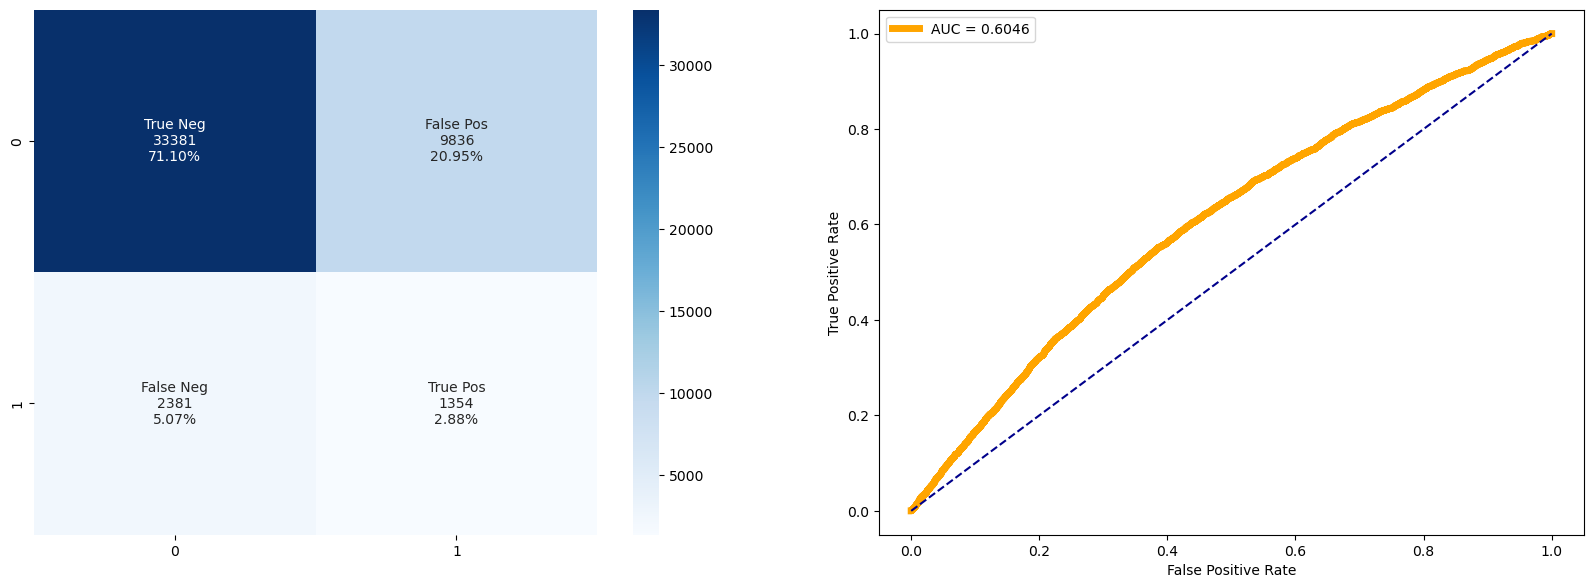

In [29]:
cf_matrix_roc_auc(logreg_cv, y_test, logreg_cv.predict(X_test), logreg_cv.predict_proba(X_test)[:,1], feature_importances=None)

In [306]:
logreg_cv.best_params_

{'C': 0.001, 'penalty': 'l2'}

In [165]:
LRP = np.where(logreg_cv.predict(X_test)<=0.5, 0, 1)

In [166]:
print(fbeta_score(y_test, LRP, beta=0.1))

0.12180434385674269


In [279]:
score_proba_ = np.array([elt[1] for elt in logreg_cv.predict_proba(X_test)])

In [280]:
def range_with_floats(start, stop, step):
    while stop > start:
        yield start
        start += step
for i in range_with_floats(0, 1, 0.1):
    LRP_i = np.where(score_proba_ <=(i), 0, 1)
    print(fbeta_score(y_test, LRP_i , beta=0.1))
    print (LRP_i.sum())

0.08028095728074552
46952
0.08034911511827017
46887
0.0803690318688923
46712
0.08088933850827959
46224
0.083361741757614
43289
0.12180434385674269
11190
0.12567574632718145
919
0.08854583571564706
225
0.05241307732226259
59
0.03584738243123336
19
0.0
0


In [320]:
#premier run MLFlow Log-Reg
import mlflow

mlflow.set_experiment("Regr_Logistic_Models")
mlflow.sklearn.autolog()
with mlflow.start_run(run_name="Reg_Logistic_GridSCV"):
    clf=LogisticRegression(C=0.01, penalty='l2')
    clf.fit(X_train, y_train)

2023/04/06 00:04:04 INFO mlflow.tracking.fluent: Experiment with name 'Regr_Logistic_Models' does not exist. Creating a new experiment.
lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
2023/04/06 00:04:22 WARNING mlflow.utils.autologging_utils: MLflow autologging encountered a warning: "C:\Users\kbouh\anaconda3\lib\site-packages\mlflow\models\signature.py:130: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the mode

In [32]:
#RandomForestClassifier
from sklearn.ensemble import RandomForestClassifier

In [33]:
%%time
grid = {
    'n_estimators' : [20, 50], #nombre d'arbres de décision
    #'min_samples_leaf' : [5,10,15], #nombre de feuilles minimales dans un noeud
    #'max_features': ['auto', 'sqrt'] #nombre de features observées pour chaque arbre
}
rfc=RandomForestClassifier(class_weight='balanced')
rfc_cv=GridSearchCV(rfc,grid,scoring=f_scorer,cv=5)
rfc_cv.fit(X_train,y_train)

roc_auc = roc_auc_score(y_test, rfc_cv.predict_proba(X_test)[:,1])
print('AUC : %0.4f' %roc_auc)

print(classification_report(y_test, rfc_cv.predict(X_test)))

AUC : 0.6704
              precision    recall  f1-score   support

         0.0       0.92      1.00      0.96     43217
         1.0       0.46      0.00      0.01      3735

    accuracy                           0.92     46952
   macro avg       0.69      0.50      0.48     46952
weighted avg       0.88      0.92      0.88     46952

Wall time: 9min 29s


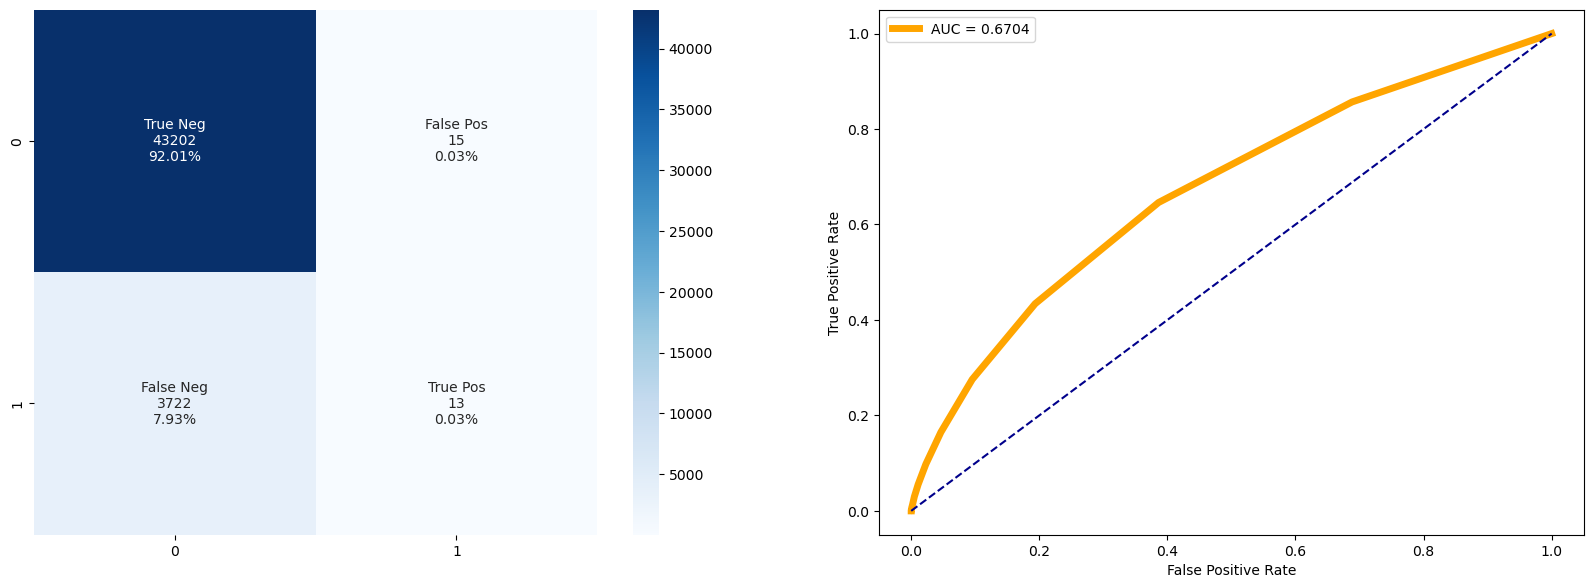

In [34]:
cf_matrix_roc_auc(rfc_cv, y_test, rfc_cv.predict(X_test), rfc_cv.predict_proba(X_test)[:,1], feature_importances=None)

In [265]:
score_proba = np.array([elt[1] for elt in rfc_cv.predict_proba(X_test)])

In [267]:
def range_with_floats(start, stop, step):
    while stop > start:
        yield start
        start += step
for i in range_with_floats(0, 1, 0.1):
    RFRP_i = np.where(score_proba <=(i), 0, 1)
    print(fbeta_score(y_test, RFRP_i , beta=0.1))
    print (RFRP_i.sum())

0.09798289240526475
32948
0.16337220035224792
9984
0.2341885497766132
2615
0.29331077747233386
672
0.2800110895481009
143
0.20091813312930376
28
0.025030978934324655
3
0.0
0
0.0
0
0.0
0
0.0
0


In [260]:
rfc_cv.predict(X_test)

array([0., 0., 0., ..., 0., 0., 0.])

In [149]:
RFRP = np.where(rfc_cv.predict(X_test)<=0.5, 0, 1)

In [150]:
print(fbeta_score(y_test, RFRP1 , beta=0.1))

0.20091813312930376


In [311]:
#premier run MLFlow RFC
import mlflow

mlflow.set_experiment("RFClassifier_Models")
mlflow.sklearn.autolog()
with mlflow.start_run(run_name="RFClassifier_GridSCV"):
    rfc=RandomForestClassifier(n_estimators=50, class_weight='balanced')
    rfc.fit(X_train, y_train)

2023/04/05 23:37:57 INFO mlflow.tracking.fluent: Experiment with name 'RFClassifier_Models' does not exist. Creating a new experiment.
2023/04/05 23:39:57 WARNING mlflow.utils.autologging_utils: MLflow autologging encountered a warning: "C:\Users\kbouh\anaconda3\lib\site-packages\mlflow\models\signature.py:130: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details."
2023/04/05 23:39:5

In [37]:
coefficients = abs(rfc_cv.best_estimator_.feature_importances_)
liste_coefs_rer = pd.concat((pd.DataFrame(X.columns, columns = ['Variable']), 
                      pd.DataFrame(coefficients, columns = ['Coefficient'])), axis = 1).sort_values(by='Coefficient', ascending = False)

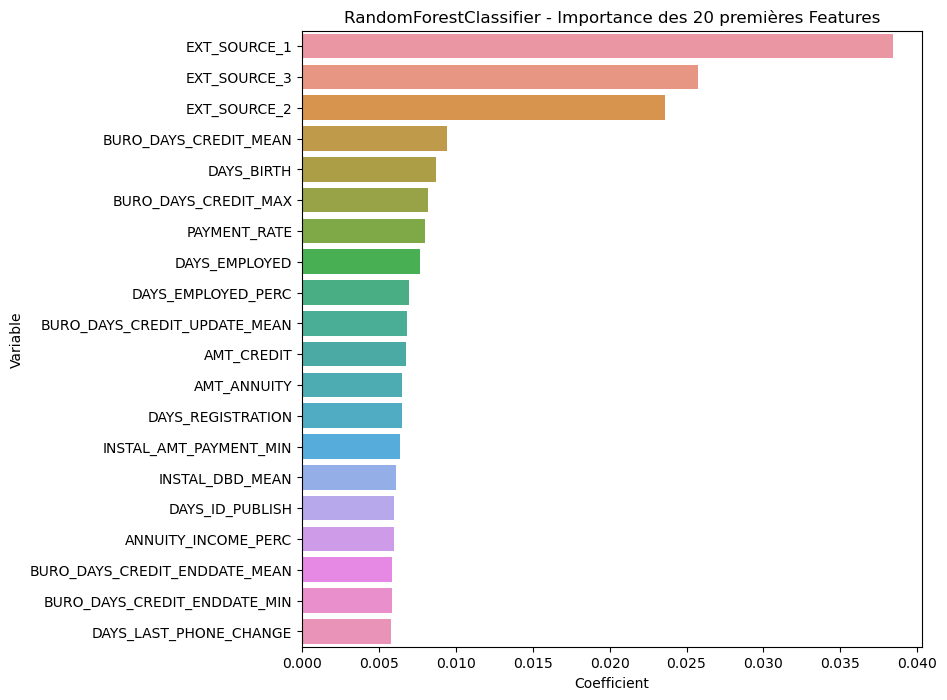

In [38]:
plt.figure(figsize=(8,8))
plt.title('RandomForestClassifier - Importance des 20 premières Features')
sns.barplot(y = liste_coefs_rer['Variable'].head(20),
            x = liste_coefs_rer['Coefficient'].head(20))
plt.show()

In [39]:
### Create a Pickle file using serialization 

#pickle_out = open("RFClassifier.pkl","wb")
#pickle.dump(rfc_cv, pickle_out)
#pickle_out.close()

In [179]:
data_reduced3 = data[['SK_ID_CURR', 'EXT_SOURCE_1', 'EXT_SOURCE_3', 'EXT_SOURCE_2','BURO_DAYS_CREDIT_MEAN', 'DAYS_BIRTH','PAYMENT_RATE','DAYS_EMPLOYED', 'TARGET']]

In [180]:
data_reduced3 

,SK_ID_CURR,EXT_SOURCE_1,EXT_SOURCE_3,EXT_SOURCE_2,BURO_DAYS_CREDIT_MEAN,DAYS_BIRTH,PAYMENT_RATE,DAYS_EMPLOYED,TARGET
0,100002,0.083037,0.139376,0.262949,-874.000000,-9461,0.060749,-637.0,1.0
1,100003,0.311267,0.466757,0.622246,-1400.750000,-16765,0.027598,-1188.0,0.0
2,100004,0.642739,0.729567,0.555912,-867.000000,-19046,0.050000,-225.0,0.0
3,100008,0.487726,0.621226,0.354225,-757.333333,-16941,0.056101,-1588.0,0.0
4,100009,0.774761,0.492060,0.724000,-1271.500000,-13778,0.026463,-3130.0,0.0
...,...,...,...,...,...,...,...,...,...
234753,456247,0.243466,0.609276,0.501221,-1043.181818,-11870,0.051433,-399.0,0.0
234754,456249,0.544286,0.742182,0.346391,-1667.076923,-24384,0.098000,0.0,0.0
234755,456253,0.744026,0.218859,0.535722,-867.500000,-14966,0.044239,-7921.0,0.0
234756,456254,0.587593,0.661024,0.514163,-1104.000000,-11961,0.054592,-4786.0,1.0


In [ ]:
#data_reduced3 = data_reduced3.to_csv('data_reduced3.csv', index=True)
#print('\nCSV String:\n', data_reduced3)

In [199]:
X1 = data_reduced3.drop(['SK_ID_CURR','TARGET'], axis=1)
y1 = data_reduced3['TARGET']

In [200]:
#Séparation jeu de données en train/test
from sklearn.model_selection import train_test_split
X1_train, X1_test, y1_train, y1_test = \
                        train_test_split(X1, 
                                         y1,  
                                         test_size = 0.2, 
                                         random_state = 42
                                        )

In [201]:
from sklearn.ensemble import RandomForestClassifier

In [202]:
rfc=RandomForestClassifier(n_estimators=50, class_weight='balanced')
rfc.fit(X1_train, y1_train)

RandomForestClassifier(class_weight='balanced', n_estimators=50)

In [203]:
RFCp = np.where(rfc.predict(X1_test)<=0.5, 0, 1)

In [204]:
print(fbeta_score(y1_test, RFCp , beta=0.1))

0.25371259697081633


In [205]:
pickle_out = open("RFClassifier3.pkl","wb")
pickle.dump(rfc, pickle_out)
pickle_out.close()

In [271]:
import gzip

In [275]:
with gzip.open("RFClassifier3.pkl", "wb") as f:
    f.write(pickle.dumps(rfc))

In [268]:
import joblib

In [270]:
joblib.dump(rfc, 'RFClassifier3.joblib', compress='zlib')

['RFClassifier3.joblib']

In [277]:

from sklearn.dummy import DummyClassifier

dummy_clf = DummyClassifier()
dummy_clf.fit(X1, y1)

DummyClassifier()

In [278]:
pickle_out = open("DummyClassifier.pkl","wb")
pickle.dump(dummy_clf, pickle_out)
pickle_out.close()

In [40]:
#from sklearn.feature_selection import RFECV

In [41]:
#rfc_cv.best_params_

In [42]:
#%%time
#start = time.time()
#rfecv = RFECV(estimator=RandomForestClassifier(n_estimators=50), 
 #             cv=5,  
 #             verbose=2,
 #             n_jobs=-1)
#rfecv.fit(X_train, y_train)

#print('Time Elapsed: {}'.format(time.time()-start))

In [43]:
#Feature importance locale : avec LIME

In [44]:
import lime
from lime import lime_tabular

In [45]:
explainer = lime_tabular.LimeTabularExplainer(X_train.to_numpy(), 
                                              mode="classification",  
                                              feature_names= list(X_train.columns)
                                              )

In [46]:
def xai_display_for_value(idx):
 
    explanation = explainer.explain_instance(X_test.iloc[idx], 
                                          rfc_cv.predict_proba, 
                                          num_features=len(list(X_test.columns)))
    explanation.show_in_notebook(show_table=True)
    return explanation

In [47]:
import random

In [48]:
i = random.randint(1, len(X_test))
print(xai_display_for_value(i))

C:\Users\kbouh\AppData\Roaming\Python\Python39\site-packages\sklearn\base.py:420: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [49]:
expl = xai_display_for_value(2)
expl.as_list()

C:\Users\kbouh\AppData\Roaming\Python\Python39\site-packages\sklearn\base.py:420: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


[('BURO_CREDIT_ACTIVE_Bad debt_MEAN <= 0.00', -0.05427053477930474),
 ('ORGANIZATION_TYPE_Religion <= 0.00', -0.04709551127634346),
 ('CLOSED_AMT_CREDIT_SUM_OVERDUE_MEAN <= 0.00', 0.036863678702445835),
 ('BURO_CREDIT_TYPE_Loan for the purchase of equipment_MEAN <= 0.00',
  -0.03508368991608455),
 ('PREV_NAME_CASH_LOAN_PURPOSE_Buying a holiday home / land_MEAN <= 0.00',
  0.034395830935811965),
 ('OCCUPATION_TYPE_HR staff <= 0.00', 0.03172018269617891),
 ('OCCUPATION_TYPE_IT staff <= 0.00', -0.030657684743494656),
 ('CLOSED_CREDIT_DAY_OVERDUE_MEAN <= 0.00', -0.030385487134702557),
 ('PREV_NAME_PORTFOLIO_Cars_MEAN <= 0.00', -0.030240051326865035),
 ('ORGANIZATION_TYPE_Restaurant <= 0.00', -0.02960634402392933),
 ('ORGANIZATION_TYPE_Industry: type 1 <= 0.00', 0.02802893846509222),
 ('PREV_NAME_GOODS_CATEGORY_Weapon_MEAN <= 0.00', 0.027845763215843044),
 ('PREV_NAME_TYPE_SUITE_Group of people_MEAN <= 0.00', -0.027587570989381173),
 ('OCCUPATION_TYPE_Secretaries <= 0.00', -0.02739843959779

In [50]:
#Feature importance globale avec SHAP

In [51]:
import shap
import sklearn
#Prétraitement des données avec StandardScaler
from sklearn import preprocessing
scaler = preprocessing.StandardScaler()
#X_train_scaled = scaler.transform(X_train)
#X_test_scaled = scaler.transform(X_test)

In [56]:
X_train.columns

Index(['Unnamed: 0.1', 'Unnamed: 0', 'index', 'SK_ID_CURR', 'CODE_GENDER',
       'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL',
       'AMT_CREDIT',
       ...
       'INSTAL_AMT_INSTALMENT_MEAN', 'INSTAL_AMT_INSTALMENT_SUM',
       'INSTAL_AMT_PAYMENT_MIN', 'INSTAL_AMT_PAYMENT_MAX',
       'INSTAL_AMT_PAYMENT_MEAN', 'INSTAL_AMT_PAYMENT_SUM',
       'INSTAL_DAYS_ENTRY_PAYMENT_MAX', 'INSTAL_DAYS_ENTRY_PAYMENT_MEAN',
       'INSTAL_DAYS_ENTRY_PAYMENT_SUM', 'INSTAL_COUNT'],
      dtype='object', length=559)

In [57]:
model = RandomForestClassifier(n_estimators=50, class_weight='balanced')
model.fit(X_train,y_train)

# explain first sample from test data
start_time = time.time()
explainer = shap.Explainer(model.predict, X_test, max_evals = 1120)
shap_values = explainer(X_test)
elapsed_time = time.time() - start_time





Permutation explainer: 46953it [30:49:21,  2.36s/it]                                                                   


In [59]:
from scipy.special import softmax

def print_feature_importances_shap_values(shap_values, features):
    '''
    Prints the feature importances based on SHAP values in an ordered way
    shap_values -> The SHAP values calculated from a shap.Explainer object
    features -> The name of the features, on the order presented to the explainer
    '''
    # Calculates the feature importance (mean absolute shap value) for each feature
    importances = []
    for i in range(shap_values.values.shape[1]):
        importances.append(np.mean(np.abs(shap_values.values[:, i])))
    # Calculates the normalized version
    importances_norm = softmax(importances)
    # Organize the importances and columns in a dictionary
    feature_importances = {fea: imp for imp, fea in zip(importances, features)}
    feature_importances_norm = {fea: imp for imp, fea in zip(importances_norm, features)}
    # Sorts the dictionary
    feature_importances = {k: v for k, v in sorted(feature_importances.items(), key=lambda item: item[1], reverse = True)}
    feature_importances_norm= {k: v for k, v in sorted(feature_importances_norm.items(), key=lambda item: item[1], reverse = True)}
    # Prints the feature importances
    for k, v in feature_importances.items():
        print(f"{k} -> {v:.4f} (softmax = {feature_importances_norm[k]:.4f})")

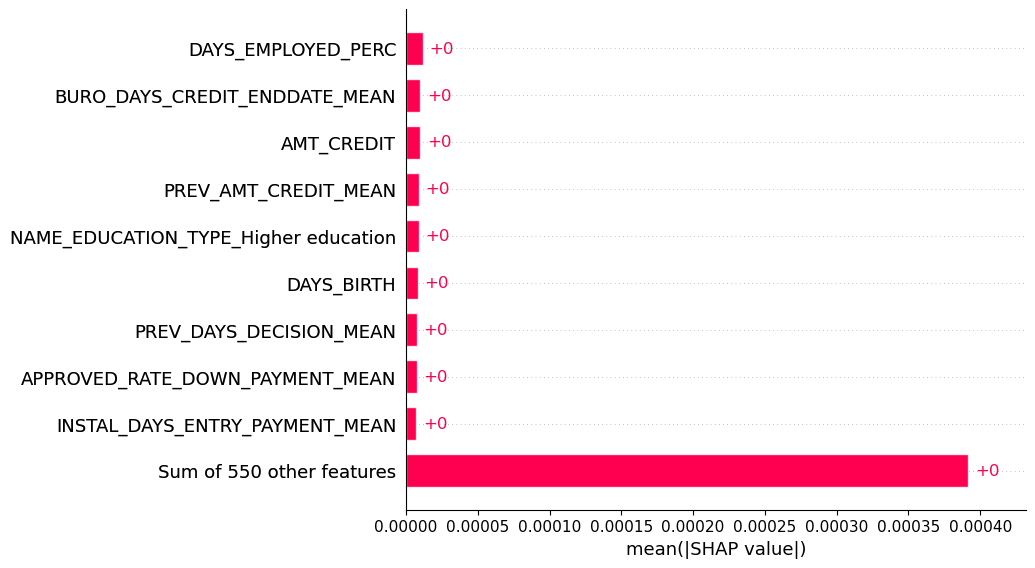

In [60]:
shap.plots.bar(shap_values)

In [114]:
importances = model.feature_importances_

In [115]:
std = np.std([tree.feature_importances_ for tree in model.estimators_], axis=0)
std[0:10]

array([0.00094491, 0.00076723, 0.00079898, 0.00067797, 0.00164977,
       0.00034902, 0.00030658, 0.00037096, 0.00074405, 0.00098249])

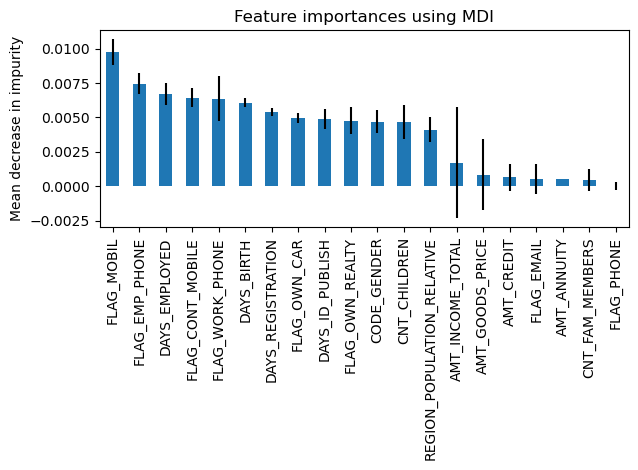

In [129]:
forest_importances = pd.Series(importances[0:20], index=X_train.columns[0:24].drop(['Unnamed: 0', 'index', 'Unnamed: 0.1', 'SK_ID_CURR'])).sort_values(ascending=False)

fig, ax = plt.subplots()
forest_importances.plot.bar(yerr=std[0:20], ax=ax)
ax.set_title("Feature importances using MDI")
ax.set_ylabel("Mean decrease in impurity")
fig.tight_layout()

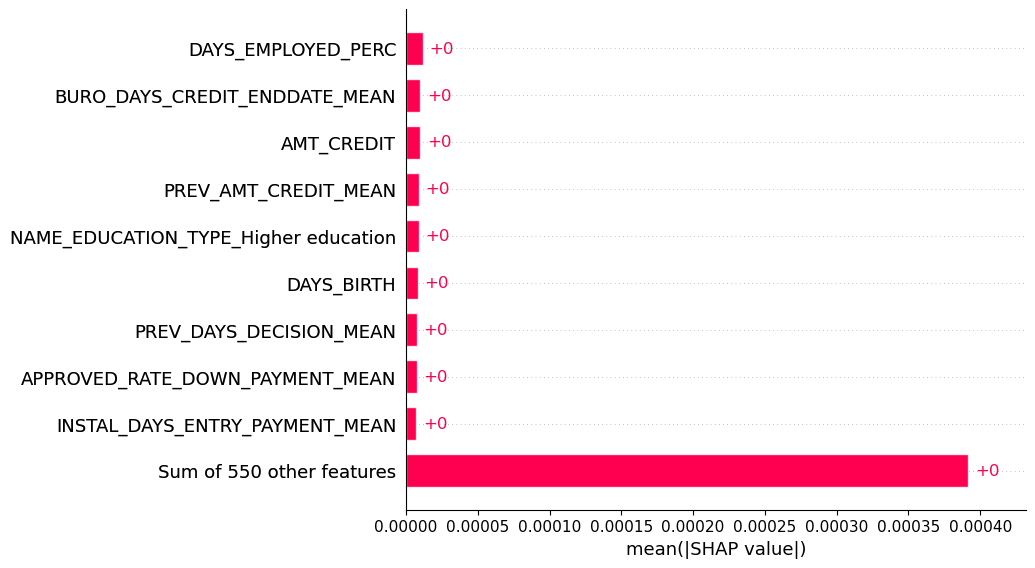

In [117]:
shap.plots.bar(shap_values)

In [108]:
forest_importances

Unnamed: 0.1                  0.0
Unnamed: 0                    0.0
index                         0.0
SK_ID_CURR                    0.0
CODE_GENDER                   0.0
FLAG_OWN_CAR                  0.0
FLAG_OWN_REALTY               0.0
CNT_CHILDREN                  0.0
AMT_INCOME_TOTAL              0.0
AMT_CREDIT                    0.0
AMT_ANNUITY                   0.0
AMT_GOODS_PRICE               0.0
REGION_POPULATION_RELATIVE    0.0
DAYS_BIRTH                    0.0
DAYS_EMPLOYED                 0.0
DAYS_REGISTRATION             0.0
DAYS_ID_PUBLISH               0.0
FLAG_MOBIL                    0.0
FLAG_EMP_PHONE                0.0
FLAG_WORK_PHONE               0.0
dtype: float64

No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored


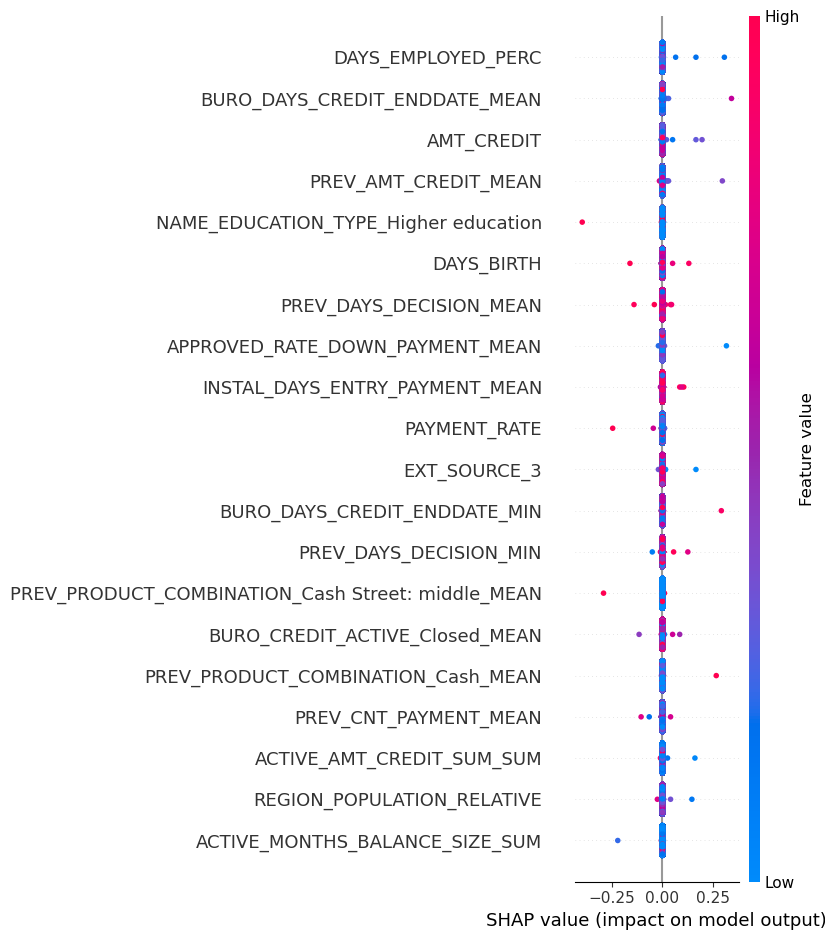

In [104]:
shap.summary_plot(shap_values, X_test)

In [101]:
#print("Tree Explainer SHAP run time", round(elapsed_time,3) , " seconds. ", current_model["name"])
#print("SHAP expected value", explainer.expected_value)
#print("Model mean value", clf.predict_proba(scaled_train_data).mean(axis=0))
#print("Model prediction for test data", clf.predict_proba(X_test))
#shap.initjs()
#pred_ind = 0
#shap.force_plot(explainer.expected_value[1], shap_values[1][0], X_test[0], feature_names=X_train.columns)

In [128]:
#model=RandomForestClassifier(n_estimators=50, class_weight='balanced')
#model=rfc_cv

In [129]:
#explainer = shap.KernelExplainer(model.predict_proba, X_train, link="logit")
#shap_values = explainer.shap_values(X_test, nsamples=100)

In [167]:
#shap.sample(X_test, nsamples=10000)

In [206]:
#explainer= shap.TreeExplainer(model.predict_proba)
#shap_values = explainer(X_test).values

In [39]:
#Pipeline de prédiction

In [40]:
#from sklearn.ensemble import GradientBoostingRegressor

In [207]:
data_reduced3

,SK_ID_CURR,EXT_SOURCE_1,EXT_SOURCE_3,EXT_SOURCE_2,BURO_DAYS_CREDIT_MEAN,DAYS_BIRTH,PAYMENT_RATE,DAYS_EMPLOYED,TARGET
0,100002,0.083037,0.139376,0.262949,-874.000000,-9461,0.060749,-637.0,1.0
1,100003,0.311267,0.466757,0.622246,-1400.750000,-16765,0.027598,-1188.0,0.0
2,100004,0.642739,0.729567,0.555912,-867.000000,-19046,0.050000,-225.0,0.0
3,100008,0.487726,0.621226,0.354225,-757.333333,-16941,0.056101,-1588.0,0.0
4,100009,0.774761,0.492060,0.724000,-1271.500000,-13778,0.026463,-3130.0,0.0
...,...,...,...,...,...,...,...,...,...
234753,456247,0.243466,0.609276,0.501221,-1043.181818,-11870,0.051433,-399.0,0.0
234754,456249,0.544286,0.742182,0.346391,-1667.076923,-24384,0.098000,0.0,0.0
234755,456253,0.744026,0.218859,0.535722,-867.500000,-14966,0.044239,-7921.0,0.0
234756,456254,0.587593,0.661024,0.514163,-1104.000000,-11961,0.054592,-4786.0,1.0


In [209]:
X1 = data_reduced3.drop(['SK_ID_CURR','TARGET'], axis=1)
y1 = data_reduced3['TARGET']

In [222]:
X1_train, X1_test, y1_train, y1_test = \
                        train_test_split(X1, 
                                         y1,  
                                         test_size = 0.2, 
                                         random_state = 42
                                        )

In [223]:
from sklearn import datasets, preprocessing, model_selection, ensemble, pipeline
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

In [232]:
classifier = ensemble.RandomForestClassifier(n_estimators=50, class_weight='balanced')
#params = {'learning_rate': [1e-1, 2e-1, 3e-1],
          #'max_depth': [2, 4, 5],
          #'min_samples_leaf': [30, 31, 32],
          #'max_iter': [100, 150]
          #}
#gsv = model_selection.GridSearchCV(classifier, params, cv=5)
classifier.fit(X1_train, y1_train)

RandomForestClassifier(class_weight='balanced', n_estimators=50)

In [237]:
#classifier.best_score_, 
#classifier.best_params_

In [239]:
#classifier.predict(X1_test, y1_test)

In [281]:
pipeline_rfc = pipeline.Pipeline([('scaler', preprocessing.StandardScaler()), 
                              ('classifier', classifier)])

In [282]:
pipeline_rfc.fit(X1_train, y1_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=50))])

In [283]:
pipeline_rfc.score(X1_test, y1_test)

0.9196626341795877

In [284]:
import joblib

In [285]:
joblib.dump(pipeline_rfc, 'pipeline_loan_RandomForestClassifier.joblib')

['pipeline_loan_RandomForestClassifier.joblib']

In [286]:
#pip install mlflow --user

In [287]:
from mlflow.models.signature import infer_signature

In [288]:
signature = infer_signature(X1_train, y1_train)

Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.


In [289]:
import mlflow

In [291]:
mlflow.sklearn.save_model(pipeline_rfc, 'mlflow_model_RandomForestClassifier2', signature=signature)

2023/04/05 19:00:06 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: mlflow_model_RandomForestClassifier2\model.pkl, flavor: sklearn), fall back to return ['scikit-learn==1.2.1', 'cloudpickle==2.0.0']. Set logging level to DEBUG to see the full traceback.


In [312]:
#second run MLFlow RFC


mlflow.set_experiment("RFClassifier_Reduced_Models")
mlflow.sklearn.autolog()
with mlflow.start_run(run_name="RFClassifier_Reduced_GridSCV"):
    rfc=RandomForestClassifier(n_estimators=50, class_weight='balanced')
    rfc.fit(X1_train, y1_train)

2023/04/05 23:49:03 INFO mlflow.tracking.fluent: Experiment with name 'RFClassifier_Reduced_Models' does not exist. Creating a new experiment.
2023/04/05 23:49:47 WARNING mlflow.utils.autologging_utils: MLflow autologging encountered a warning: "C:\Users\kbouh\anaconda3\lib\site-packages\mlflow\models\signature.py:130: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details."
2023/04/05

In [313]:
from pyngrok import ngrok

In [314]:

# Terminate open tunnels if exist
ngrok.kill()

# Setting the authtoken (optional)
# Get your authtoken from https://dashboard.ngrok.com/auth
NGROK_AUTH_TOKEN = "2O1BppPcAa57dEZQG8XqCVk8Zqy_6AhmMTs9rNFmPrqjEQSsA" 
ngrok.set_auth_token(NGROK_AUTH_TOKEN)

# Open an HTTPs tunnel on port 5000 for http://localhost:5000
ngrok_tunnel = ngrok.connect(addr="5000", proto="http", bind_tls=True)
print("MLflow Tracking UI:", ngrok_tunnel.public_url)

MLflow Tracking UI: https://7123-2a01-e0a-20d-f3a0-91f0-fc67-51b0-6e31.ngrok.io                     


In [316]:
!mlflow ui

Traceback (most recent call last):
  File "C:\Users\kbouh\anaconda3\lib\runpy.py", line 197, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "C:\Users\kbouh\anaconda3\lib\runpy.py", line 87, in _run_code
    exec(code, run_globals)
  File "C:\Users\kbouh\anaconda3\Scripts\mlflow.exe\__main__.py", line 4, in <module>
  File "C:\Users\kbouh\anaconda3\lib\site-packages\mlflow\__init__.py", line 41, in <module>
    from mlflow import projects  # pylint: disable=unused-import
  File "C:\Users\kbouh\anaconda3\lib\site-packages\mlflow\projects\__init__.py", line 28, in <module>
    from mlflow.projects.backend import loader
  File "C:\Users\kbouh\anaconda3\lib\site-packages\mlflow\projects\backend\loader.py", line 4, in <module>
    from mlflow.projects.backend.local import LocalBackend
  File "C:\Users\kbouh\anaconda3\lib\site-packages\mlflow\projects\backend\local.py", line 32, in <module>
    from mlflow.utils.virtualenv import (
  File "C:\Users\kbouh\anaconda